In [1]:
   import pandas as pd

   df = pd.read_excel("../data/default of credit card clients.xls", header=1)
   print(df.shape)
   df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


# Exploratory Data Analysis
## 1. Initial inspection

In [3]:
# Data types and non-null counts for each column
df.info()

# Missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate rows (excluding ID, which is always unique)
print("\nDuplicate rows:", df.drop(columns="ID").duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

## 2. Data cleaning

In [4]:
# Rename columns for clarity
df = df.rename(columns={"PAY_0": "PAY_1",
                        "default payment next month": "default"})

# Drop ID (not useful for prediction)
df = df.drop(columns="ID")

# Remove duplicate rows
df = df.drop_duplicates()

# Undocumented categories before cleaning
print("BEFORE")
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE:", df["MARRIAGE"].value_counts().sort_index().to_dict())

# Group undocumented values into 'others'
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

# Check after cleaning
print("\nAFTER")
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE:", df["MARRIAGE"].value_counts().sort_index().to_dict())
print("\nShape:", df.shape)

BEFORE
EDUCATION: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE: {0: 54, 1: 13643, 2: 15945, 3: 323}

AFTER
EDUCATION: {1: 10563, 2: 14019, 3: 4915, 4: 468}
MARRIAGE: {1: 13643, 2: 15945, 3: 377}

Shape: (29965, 24)


## 3. Target variable

         count  percent
default                
0        23335    77.87
1         6630    22.13


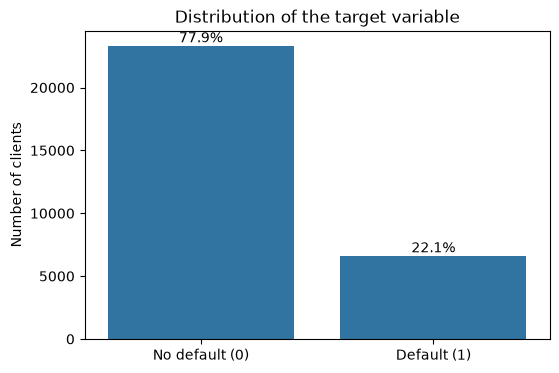

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count and percentage of each class
counts = df["default"].value_counts().sort_index()
percent = df["default"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

# Bar chart of the target
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="default", data=df)
plt.xticks([0, 1], ["No default (0)", "Default (1)"])
plt.title("Distribution of the target variable")
plt.xlabel("")
plt.ylabel("Number of clients")

# Add percentage labels on top of the bars
ax.bar_label(ax.containers[0], labels=[f"{p:.1f}%" for p in percent])

# Save the figure for the report and slides
plt.savefig("../figures/target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Summary statistics

In [6]:
# Numerical columns
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
num_cols = ["LIMIT_BAL", "AGE"] + bill_cols + pay_amt_cols

# Summary statistics (transposed for readability)
display(df[num_cols].describe().T.round(0))

# Number of negative bill amounts per month
print("Negative bill amounts:")
print((df[bill_cols] < 0).sum())

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,29965.0,167442.0,129760.0,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,29965.0,35.0,9.0,21.0,28.0,34.0,41.0,79.0
BILL_AMT1,29965.0,51283.0,73658.0,-165580.0,3595.0,22438.0,67260.0,964511.0
BILL_AMT2,29965.0,49236.0,71196.0,-69777.0,3010.0,21295.0,64109.0,983931.0
BILL_AMT3,29965.0,47068.0,69371.0,-157264.0,2711.0,20135.0,60201.0,1664089.0
BILL_AMT4,29965.0,43313.0,64354.0,-170000.0,2360.0,19081.0,54601.0,891586.0
BILL_AMT5,29965.0,40358.0,60817.0,-81334.0,1787.0,18130.0,50247.0,927171.0
BILL_AMT6,29965.0,38917.0,59574.0,-339603.0,1262.0,17124.0,49252.0,961664.0
PAY_AMT1,29965.0,5670.0,16572.0,0.0,1000.0,2102.0,5008.0,873552.0
PAY_AMT2,29965.0,5928.0,23053.0,0.0,850.0,2010.0,5000.0,1684259.0


Negative bill amounts:
BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688
dtype: int64


## 5a. Distributions

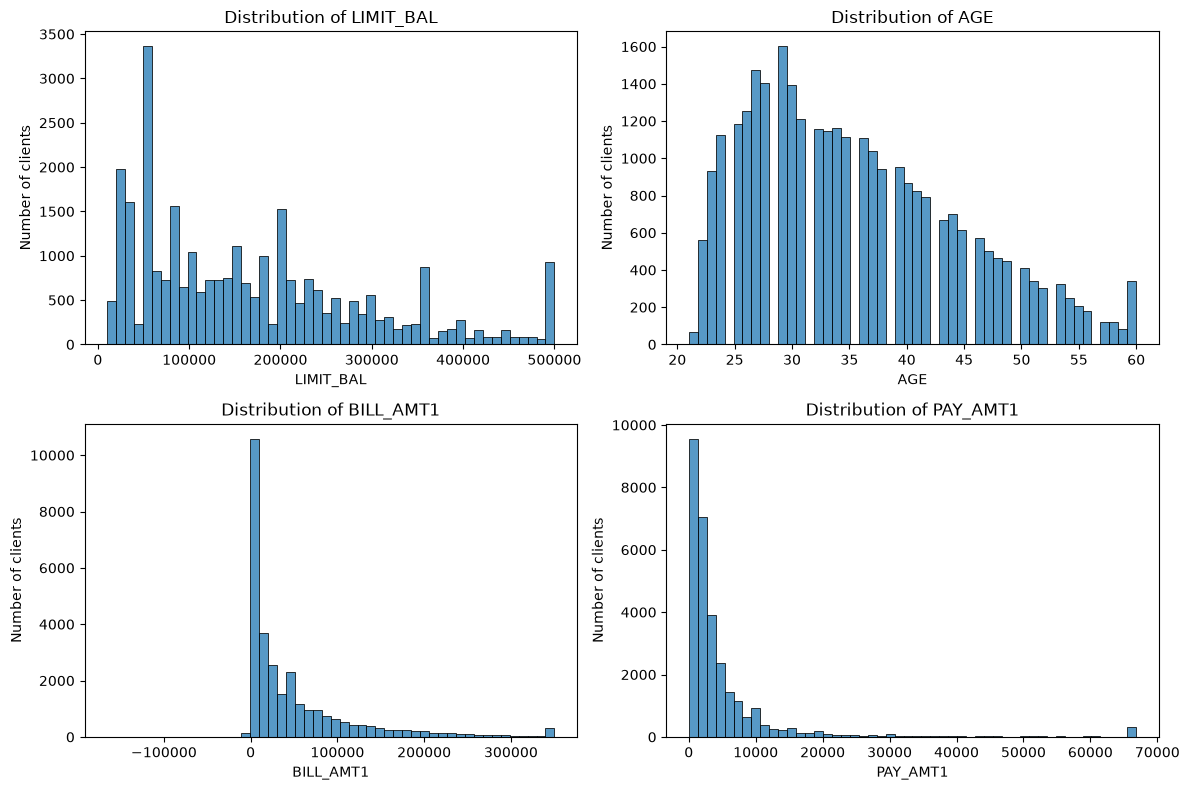

In [7]:
# Histograms of numerical variables (top 1% clipped for readability)
num_to_plot = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, num_to_plot):
    data = df[col].clip(upper=df[col].quantile(0.99))
    sns.histplot(data, bins=50, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Number of clients")

plt.tight_layout()
plt.savefig("../figures/numerical_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

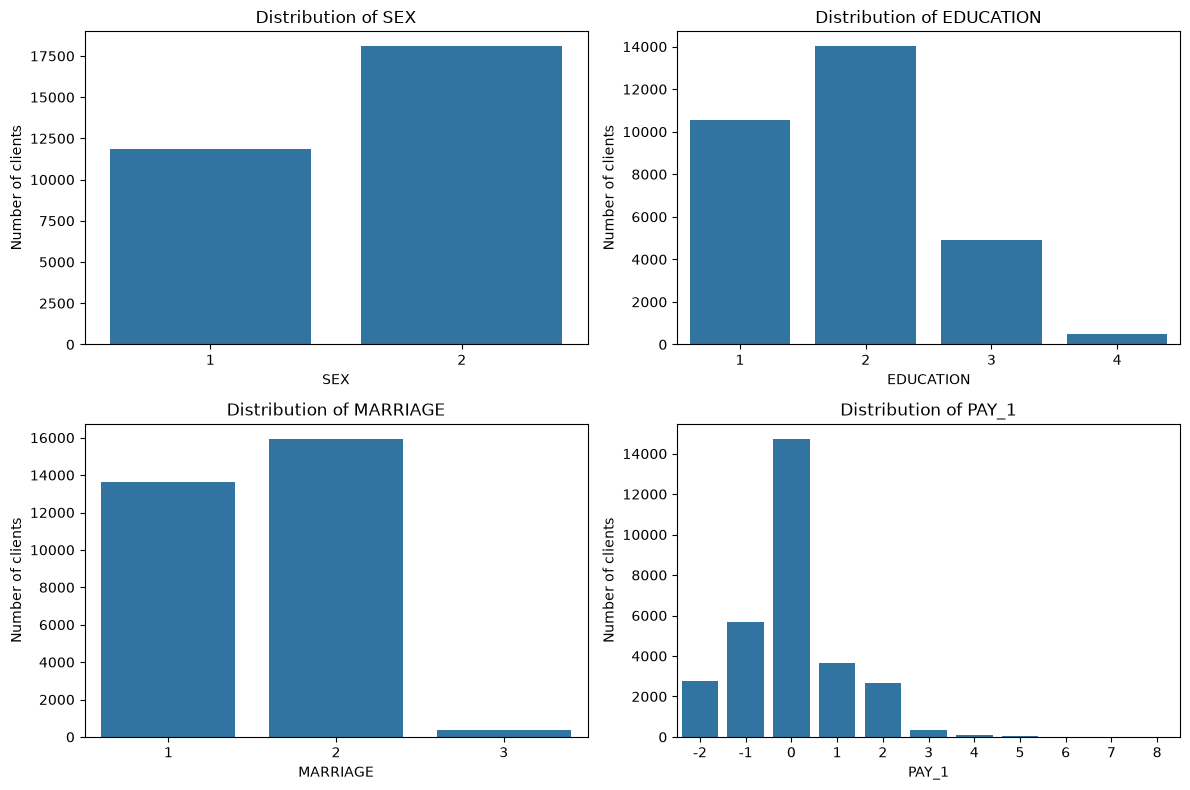

In [8]:
# Bar charts of categorical variables
cat_cols = ["SEX", "EDUCATION", "MARRIAGE", "PAY_1"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Number of clients")

plt.tight_layout()
plt.savefig("../figures/categorical_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 5b. Outliers

           outliers  percent
LIMIT_BAL       167      0.6
AGE             272      0.9
BILL_AMT1      2386      8.0
BILL_AMT2      2390      8.0
BILL_AMT3      2469      8.2
BILL_AMT4      2616      8.7
BILL_AMT5      2724      9.1
BILL_AMT6      2688      9.0
PAY_AMT1       2742      9.2
PAY_AMT2       2723      9.1
PAY_AMT3       2596      8.7
PAY_AMT4       2993     10.0
PAY_AMT5       2944      9.8
PAY_AMT6       2960      9.9


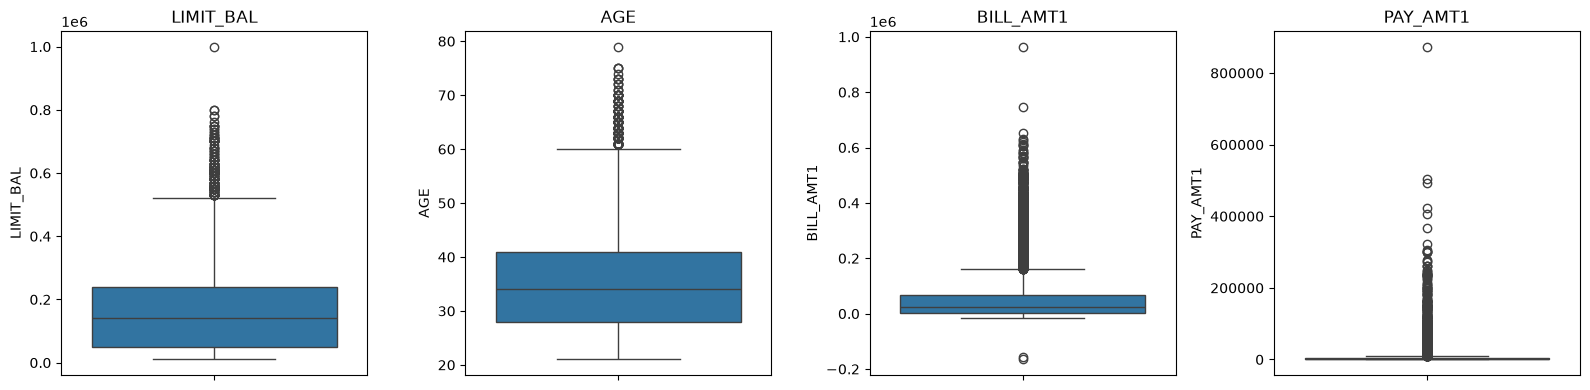

In [14]:
# Outlier detection with the IQR rule
outlier_counts = {}
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_counts[col] = ((df[col] < lower) | (df[col] > upper)).sum()

outliers = pd.Series(outlier_counts)
print(pd.DataFrame({"outliers": outliers,
                    "percent": (outliers / len(df) * 100).round(1)}))

# Boxplots of selected variables
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.savefig("../figures/outliers_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Correlations

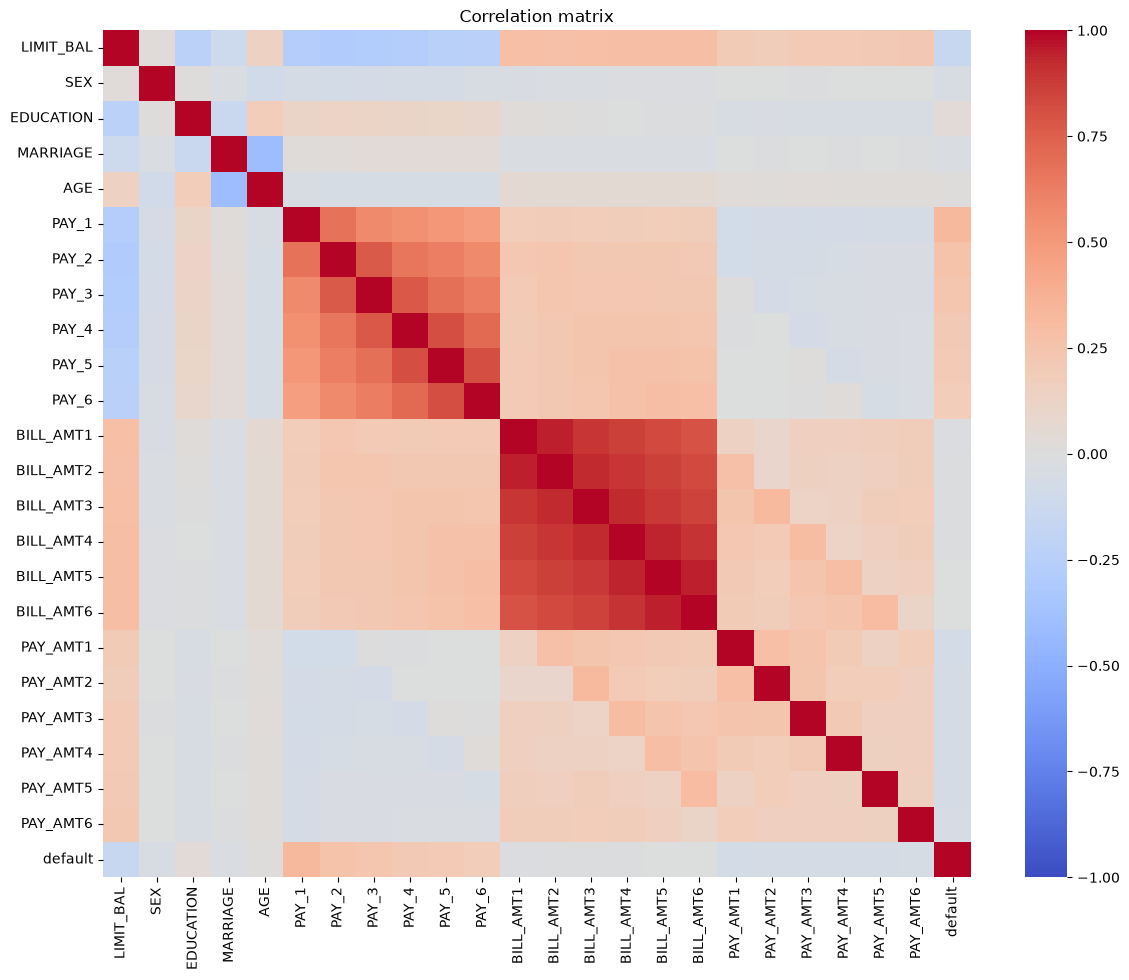

In [9]:
# Correlation matrix of all variables
corr = df.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.savefig("../figures/correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
PAY_AMT3    -0.056
PAY_AMT5    -0.055
PAY_AMT6    -0.053
SEX         -0.040
MARRIAGE    -0.027
BILL_AMT1   -0.020
BILL_AMT2   -0.014
BILL_AMT3   -0.014
BILL_AMT4   -0.010
BILL_AMT5   -0.007
BILL_AMT6   -0.005
AGE          0.014
EDUCATION    0.034
PAY_6        0.187
PAY_5        0.204
PAY_4        0.217
PAY_3        0.235
PAY_2        0.264
PAY_1        0.325
Name: default, dtype: float64


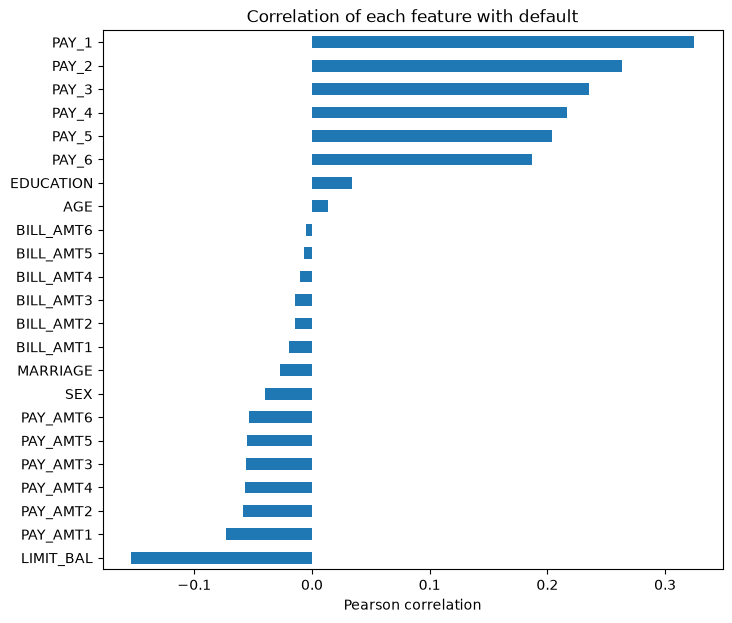

In [10]:
# Correlation of each feature with the target
target_corr = corr["default"].drop("default").sort_values()
print(target_corr.round(3))

plt.figure(figsize=(8, 7))
target_corr.plot(kind="barh")
plt.title("Correlation of each feature with default")
plt.xlabel("Pearson correlation")
plt.savefig("../figures/correlation_with_target.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Default rate by client group

In [11]:
# Copy of the data for EDA-only grouping columns
df_eda = df.copy()

# Bins for continuous variables
df_eda["LIMIT_BAL_group"] = pd.cut(
    df_eda["LIMIT_BAL"],
    bins=[0, 50000, 100000, 200000, 300000, 500000, 1000000],
    labels=["≤50k", "50–100k", "100–200k", "200–300k", "300–500k", ">500k"])

df_eda["AGE_group"] = pd.cut(
    df_eda["AGE"],
    bins=[20, 30, 40, 50, 60, 80],
    labels=["21–30", "31–40", "41–50", "51–60", "61+"])

# Readable labels for categorical variables
df_eda["SEX_label"] = df_eda["SEX"].map({1: "Male", 2: "Female"})
df_eda["EDUCATION_label"] = df_eda["EDUCATION"].map(
    {1: "Graduate", 2: "University", 3: "High school", 4: "Others"})
df_eda["MARRIAGE_label"] = df_eda["MARRIAGE"].map(
    {1: "Married", 2: "Single", 3: "Others"})

# Group long delays (4+ months) together: very few clients
df_eda["PAY_1_group"] = df_eda["PAY_1"].clip(upper=4)


Default rate (%) by LIMIT_BAL_group:
LIMIT_BAL_group
≤50k        31.8
50–100k     25.8
100–200k    19.5
200–300k    16.0
300–500k    13.3
>500k       11.2
Name: default, dtype: float64

Default rate (%) by AGE_group:
AGE_group
21–30    22.5
31–40    20.4
41–50    23.3
51–60    25.2
61+      26.8
Name: default, dtype: float64

Default rate (%) by SEX_label:
SEX_label
Female    20.8
Male      24.2
Name: default, dtype: float64

Default rate (%) by EDUCATION_label:
EDUCATION_label
Graduate       19.2
High school    25.2
Others          7.1
University     23.7
Name: default, dtype: float64

Default rate (%) by MARRIAGE_label:
MARRIAGE_label
Married    23.5
Others     23.6
Single     20.9
Name: default, dtype: float64

Default rate (%) by PAY_1_group:
PAY_1_group
-2    13.2
-1    16.8
 0    12.8
 1    34.0
 2    69.1
 3    75.8
 4    63.1
Name: default, dtype: float64


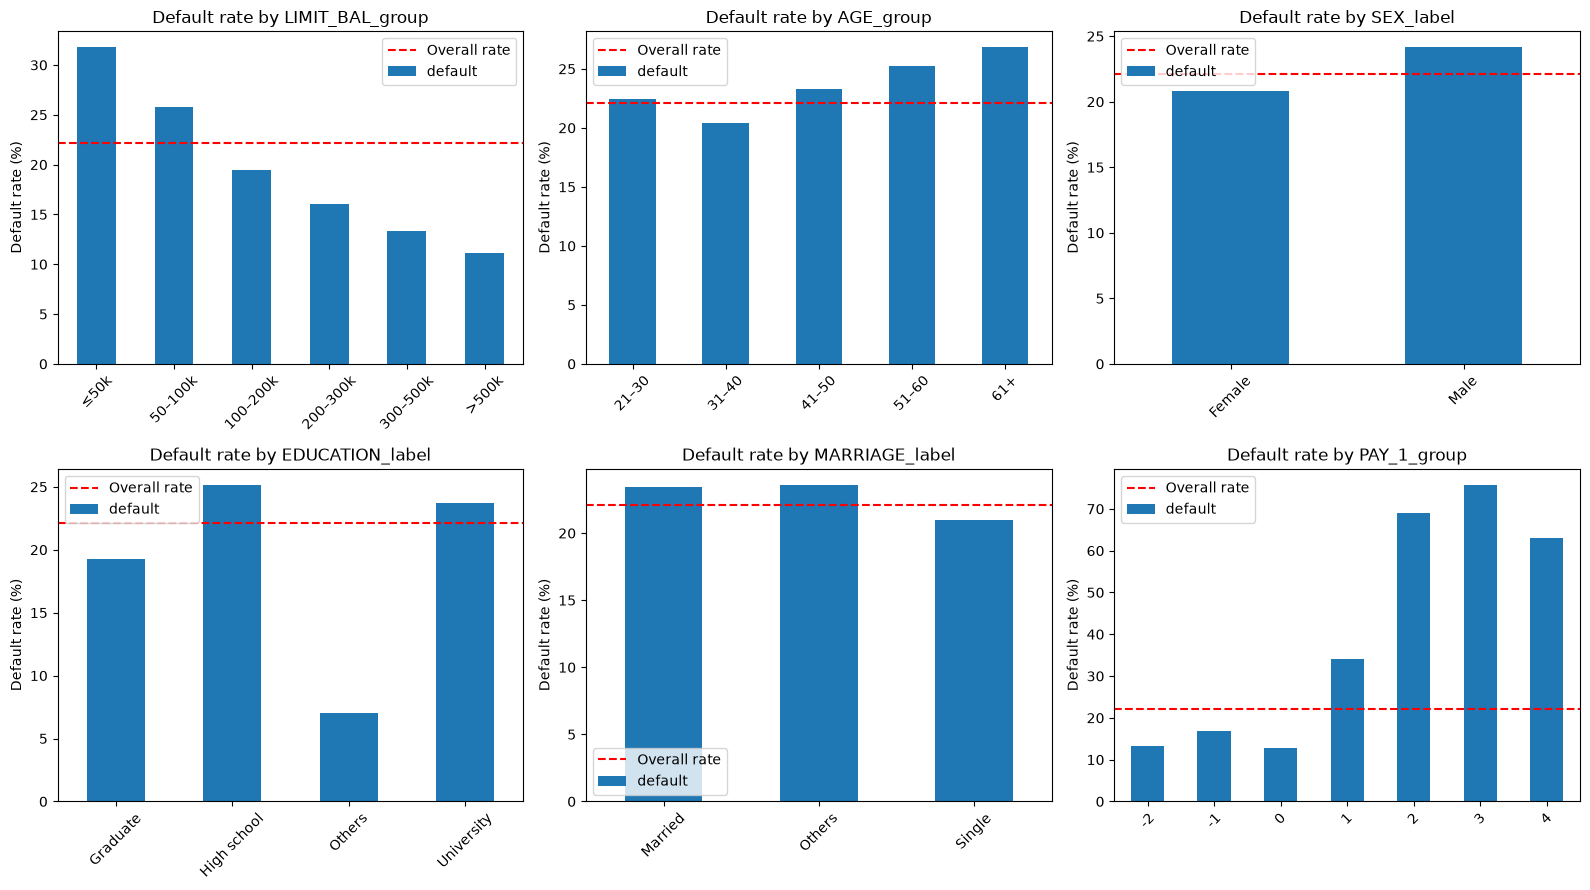

In [12]:
groups = ["LIMIT_BAL_group", "AGE_group", "SEX_label",
          "EDUCATION_label", "MARRIAGE_label", "PAY_1_group"]
overall_rate = df["default"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, groups):
    rate = df_eda.groupby(col, observed=True)["default"].mean() * 100
    print(f"\nDefault rate (%) by {col}:")
    print(rate.round(1))

    rate.plot(kind="bar", ax=ax)
    ax.axhline(overall_rate, color="red", linestyle="--", label="Overall rate")
    ax.set_title(f"Default rate by {col}")
    ax.set_ylabel("Default rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.tight_layout()
plt.savefig("../figures/default_rate_by_group.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Key findings

**Data quality**
- 30,000 clients, 25 variables, no missing values; 35 duplicate rows removed.
- Undocumented codes in EDUCATION (0, 5, 6) and MARRIAGE (0) were grouped into "others" (<2% of clients).
- `PAY_0` renamed to `PAY_1` for consistency; negative bill amounts kept (customer credit balances).

**Target**
- The target is imbalanced: ~22% of clients default. Accuracy is not a suitable metric;
  we will use recall, precision, F1, ROC-AUC and PR-AUC, with a stratified split.

**Distributions, correlations and outliers**
- Monetary variables (LIMIT_BAL, BILL_AMT, PAY_AMT) are strongly right-skewed with very different scales → scaling needed.
- The six BILL_AMT variables are highly correlated with each other (~0.8–0.95), and so are the PAY variables → redundancy.
- Outliers: using the IQR rule, about {{8–10%}} of the values of each bill and payment amount are outliers, while LIMIT_BAL and AGE have fewer than {{1%}}. These are genuine large balances and payments rather than data entry errors, so we kept them. Their influence will be handled with a log transformation or robust scaling for scale-sensitive models, while tree-based models are naturally robust to them.

**Default risk by group**
- Payment history is the strongest signal: clients 2+ months late in September default ~70% of the time vs. ~13–17% for clients in good standing.
- Default rate decreases as the credit limit increases (~32% for ≤50k vs. ~10–12% above 300k).
- Demographic differences are smaller: men default more than women (~24% vs. ~21%), and the age pattern is U-shaped.
  These differences motivate the fairness analysis planned for the final report.